# TP3 Homework — Fine-tuning Gemma 3 (4B) with LoRA on a Khmer Banking FAQ dataset

**Student:** Kong Sattha · **Course:** ADV (Year 5) · **Base notebook:** `Gemma3_(4B).ipynb` (kept unchanged as the original)

This notebook covers the four learning objectives of the homework:

| # | Objective | Where in this notebook |
|---|-----------|------------------------|
| 1 | **Course summary** — LLM fine-tuning workflow, Gemma 3, LoRA, PEFT, dataset preparation | Sections 1–5 (each step explained) |
| 2 | **Notebook configuration** — understand & modify training hyperparameters | Section 2 (`CONFIG` cell: original value → new value → reason) |
| 3 | **Loss analysis** — monitor Training Loss vs Validation Loss, detect over/underfitting | Sections 7–8 |
| 4 | **Practical experiment** — fine-tune on a *different dataset* and compare results | Sections 4, 9, 10 |

**What changed vs the original notebook**

* **New dataset:** `dataasilida_cleaned.csv` — 500+ Khmer question→answer pairs about Cambodian banking (ACLEDA cards, accounts, loans, NBC/riel …) instead of `data_kh.csv` (Khmer robot-movement commands → JSON).
* **Validation set added** (the original trained with `eval_dataset=None`, so it could not detect overfitting).
* **Loss curves + automatic diagnosis** of underfitting / good fit / overfitting.
* **Before vs after comparison** of answers with a character-level metric (chrF) suited to Khmer.
* **Up-to-date installation** (the original pinned March-2025 versions that no longer install on Colab).
* **Bug fix:** the original produced a double `<bos><bos>` token at the start of each training example.

> ▶️ **How to run:** `Runtime → Change runtime type → T4 GPU`, upload `dataasilida_cleaned.csv` when asked (or drag it into the Files panel), then `Runtime → Run all`.

## 1. Installation

We use **Unsloth**, a library that makes LoRA fine-tuning ~2× faster and uses less GPU memory, so a 4-billion-parameter model fits on a free Colab **T4 (15 GB)**. It brings `transformers`, `trl` (the `SFTTrainer`), `peft` (LoRA) and `bitsandbytes` (4-bit quantization) at compatible versions.

*Why not the original install cell?* It pinned `transformers@v4.49.0-Gemma-3`, `xformers==0.0.29.post3` and `vllm`, which conflict with the current Colab PyTorch. We don't need vLLM at all (it's only for fast serving), so it's removed.

In [1]:
# Takes ~2-4 minutes. Output is kept visible so any install error is easy to spot.
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install -q unsloth          # local / other cloud
else:
    !pip install -q --upgrade unsloth unsloth_zoo   # Colab: Unsloth picks versions compatible with Colab's torch
!pip install -q sacrebleu            # chrF metric for the evaluation section

In [2]:
# Sanity check: we need a GPU (Runtime -> Change runtime type -> T4 GPU)
import torch
assert torch.cuda.is_available(), "No GPU found! In Colab: Runtime -> Change runtime type -> T4 GPU, then re-run."
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)

GPU: Tesla T4 | torch 2.14.1+cu130


## 2. Configuration — all hyperparameters in one place (Objective 2)

Every value that controls training lives in this one cell so it's easy to change and to explain.
The comment on each line shows **original value → new value** and the reason.

| Group | Hyperparameter | What it controls |
|-------|----------------|------------------|
| Model | `max_seq_length` | Longest example (in tokens) the model sees; longer = more memory |
| Model | `load_in_4bit` | Store the frozen base weights in 4-bit (QLoRA) → ~4× less memory |
| LoRA | `r` (rank) | Size of the low-rank adapter matrices = how much the model can learn |
| LoRA | `lora_alpha` | Scaling of the adapter update (effective scale = alpha / r) |
| LoRA | `lora_dropout` | Randomly drops adapter activations (regularization) |
| Training | `learning_rate` | Step size of each weight update |
| Training | `per_device_train_batch_size` × `gradient_accumulation_steps` | Effective batch size (examples per update) |
| Training | `num_train_epochs` / `max_steps` | How long we train |
| Training | `warmup_steps`, `lr_scheduler_type` | LR starts small, then decays linearly |
| Training | `weight_decay` | L2-style penalty that keeps weights small (regularization) |
| Evaluation | `eval_steps` | How often we measure **validation loss** |

In [3]:
CONFIG = dict(
    # ---------------- model ----------------
    model_name      = "unsloth/gemma-3-4b-it",  # same as original: Gemma 3, 4B, instruction-tuned
    max_seq_length  = 2048,   # same. Banking answers are long (up to ~2,800 Khmer characters); checked in section 4
    load_in_4bit    = True,   # same: QLoRA -> fits on a T4

    # ---------------- LoRA / PEFT ----------------
    r               = 16,     # original 8  -> 16 : open-ended Q&A with long answers is harder than mapping commands to JSON,
                              #                    so give the adapter more capacity
    lora_alpha      = 16,     # original 8  -> 16 : keep alpha = r (scale 1.0), the recommended starting point
    lora_dropout    = 0,      # same: 0 is the Unsloth-optimized setting; we control overfitting with validation + best checkpoint

    # ---------------- training ----------------
    per_device_train_batch_size = 2,   # same
    gradient_accumulation_steps = 4,   # same -> effective batch = 2 x 4 = 8 examples per update
    learning_rate   = 2e-4,   # same: standard LoRA learning rate
    num_train_epochs = 3,     # original max_steps=60 -> 3 full epochs. 60 steps x 8 = 480 examples, i.e. only 16% of the
                              #   original data. Here we train longer ON PURPOSE so the curves show where overfitting starts.
                              #   (Set to 2 if your Colab session is short.)
    warmup_steps    = 5,      # same
    lr_scheduler_type = "linear",  # same
    weight_decay    = 0.01,   # same
    optim           = "adamw_8bit",  # same: 8-bit Adam saves memory
    seed            = 3407,   # same: reproducibility

    # ---------------- evaluation (NEW) ----------------
    val_fraction    = 0.10,   # NEW: hold out 10% of the questions as a validation set
    eval_steps      = 10,     # NEW: compute validation loss every 10 training steps
    load_best_model_at_end = True,  # NEW: after training keep the checkpoint with the LOWEST validation loss
    n_eval_generate = 15,     # NEW: number of validation questions used for the before/after answer comparison
)

DATA_PATH   = "dataasilida_cleaned.csv"
RESULTS_DIR = "results"      # plots / CSVs for the presentation are saved here
import os; os.makedirs(RESULTS_DIR, exist_ok=True)
CONFIG

{'model_name': 'unsloth/gemma-3-4b-it',
 'max_seq_length': 2048,
 'load_in_4bit': True,
 'r': 16,
 'lora_alpha': 16,
 'lora_dropout': 0,
 'per_device_train_batch_size': 2,
 'gradient_accumulation_steps': 4,
 'learning_rate': 0.0002,
 'num_train_epochs': 3,
 'warmup_steps': 5,
 'lr_scheduler_type': 'linear',
 'weight_decay': 0.01,
 'optim': 'adamw_8bit',
 'seed': 3407,
 'val_fraction': 0.1,
 'eval_steps': 10,
 'load_best_model_at_end': True,
 'n_eval_generate': 15}

## 3. Load Gemma 3 (4B) in 4-bit and attach LoRA adapters (PEFT)

**Gemma 3** is Google's open-weight LLM family (1B / 4B / 12B / 27B). The 4B model is multimodal (text + image) and multilingual (140+ languages, Khmer included), with a 128K context window and a 262K-token vocabulary. We use the **instruction-tuned** (`-it`) version, which already knows the chat format.

**PEFT (Parameter-Efficient Fine-Tuning)** = update only a tiny number of parameters instead of all 4 billion.
**LoRA** is the PEFT method we use: each chosen weight matrix `W` is frozen and we learn a low-rank update `ΔW = B·A` (with `A: r×k`, `B: d×r`, `r ≪ d`). Only `A` and `B` are trained. Combined with 4-bit loading this is called **QLoRA**.

We fine-tune only the **language** layers (attention + MLP); the vision tower is frozen because our data is text-only.

In [4]:
from unsloth import FastModel
from unsloth.chat_templates import get_chat_template

def build_model(cfg):
    # Load the 4-bit base model, attach LoRA adapters, set the Gemma-3 chat template.
    model, tokenizer = FastModel.from_pretrained(
        model_name     = cfg["model_name"],
        max_seq_length = cfg["max_seq_length"],
        load_in_4bit   = cfg["load_in_4bit"],
        load_in_8bit   = False,
        full_finetuning = False,
    )
    model = FastModel.get_peft_model(
        model,
        finetune_vision_layers     = False,  # text-only data -> keep vision tower frozen
        finetune_language_layers   = True,
        finetune_attention_modules = True,   # q, k, v, o projections
        finetune_mlp_modules       = True,   # gate, up, down projections
        r            = cfg["r"],
        lora_alpha   = cfg["lora_alpha"],
        lora_dropout = cfg["lora_dropout"],
        bias         = "none",
        random_state = cfg["seed"],
    )
    tokenizer = get_chat_template(tokenizer, chat_template="gemma-3")
    return model, tokenizer

model, tokenizer = build_model(CONFIG)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable LoRA parameters: {trainable:,}  ({100*trainable/total:.2f}% of the {total:,} parameters stored)")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1111 15:26:45.872000 1788 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1111 15:26:45.931000 1788 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.3: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

## 4. Dataset preparation (Objective 1 & 4)

### 4.1 Load and **repair** the CSV
The raw file has two problems we found while inspecting it:
1. The header is written as one quoted field `"input,output"` instead of two columns, so `load_dataset("csv")` / `pd.read_csv` read the whole file as **one column**.
2. **7 rows** have question and answer merged into a single quoted field (`"question ? ,answer"`), which leaves `output` empty.

We read it with Python's `csv` module, split merged rows at the first `?`, and rebuild a clean two-column table.

In [23]:
import os, csv, re, random
import pandas as pd

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print(f"'{DATA_PATH}' not found -> please upload it")
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_PATH} next to this notebook")

def load_and_repair(path):
    with open(path, encoding="utf-8-sig") as f:
        rows = list(csv.reader(f))
    records, repaired, dropped = [], 0, 0
    for r in rows[1:]:                      # rows[0] is the broken header
        if len(r) == 2:
            q, a = r
        elif len(r) == 1 and "?" in r[0]:   # merged "question ? ,answer"
            q, a = r[0].split("?", 1)
            q, a = q + "?", a.lstrip(" ,")
            repaired += 1
        else:
            dropped += 1
            continue
        records.append({"input": q, "output": a})
    return pd.DataFrame(records), repaired, dropped

raw_df, n_repaired, n_dropped = load_and_repair(DATA_PATH)
print(f"Rows read: {len(raw_df)} | merged rows repaired: {n_repaired} | unreadable rows dropped: {n_dropped}")

Rows read: 521 | merged rows repaired: 7 | unreadable rows dropped: 0


### 4.2 Clean the text
* Turn the literal two-character sequence `\n` into a real line break (answers with bullet lists).
* Remove zero-width spaces (`U+200B`) — invisible characters that Khmer websites insert as line-break hints; they only waste tokens and make identical words look different to the tokenizer.
* Collapse repeated spaces, strip, drop empty rows and exact duplicates.

In [6]:
def clean_text(s):
    s = str(s).replace("\\n", "\n").replace("​", "")
    s = re.sub(r"[ \t]+", " ", s)
    s = re.sub(r" *\n *", "\n", s)
    return s.strip()

df = raw_df.copy()
df["input"]  = df["input"].map(clean_text)
df["output"] = df["output"].map(clean_text)
before = len(df)
df = df[(df.input.str.len() > 0) & (df.output.str.len() > 0)]
df = df.drop_duplicates(subset=["input", "output"]).reset_index(drop=True)
print(f"After cleaning: {len(df)} rows (removed {before - len(df)} empty/duplicate rows)")
print(f"Questions asked more than once (same question, different answer): {df.input.duplicated(keep=False).sum()} rows")

print("\nCharacter length statistics:")
display(pd.DataFrame({"question": df.input.str.len().describe(), "answer": df.output.str.len().describe()}).round(0))
df.sample(3, random_state=1)

After cleaning: 518 rows (removed 3 empty/duplicate rows)
Questions asked more than once (same question, different answer): 52 rows

Character length statistics:


,question,answer
count,518.0,518.0
mean,61.0,321.0
std,27.0,303.0
min,16.0,20.0
25%,43.0,131.0
50%,56.0,228.0
75%,71.0,410.0
max,203.0,2802.0


,input,output
485,តើត្រូវចុះឈ្មោះប្រើប្រាស់សេវាសុវត្ថិភាព 3D អ៉ី...,សេវាសុវត្ថិភាព 3D អ៉ីអនគឺមិនតម្រូវអោយមានការចុះ...
273,តើលិខិតអះអាងលើគណនី និងព័ត៌មានអតិថិជនមានលក្ខណៈព...,អះអាងលើព័ត៌មានផ្សេងៗពាក់ព័ន្ធនឹងសេវាបញ្ញើសន្សំ...
420,ប្រសិនបើខ្ញុំបង់ប្រាក់រួចរាល់ហើយ តើខ្ញុំត្រូវប...,ប្រសិនបើលោកអ្នកធ្វើការបង់ទឹកប្រាក់មុនថ្ងៃទី ៥ ...


### 4.3 Convert to the Gemma-3 chat format
An instruction-tuned model must be trained in **the same conversation format it was pre-trained with**. Gemma 3 uses:
```
<bos><start_of_turn>user
{question}<end_of_turn>
<start_of_turn>model
{answer}<end_of_turn>
```
`tokenizer.apply_chat_template` writes this for us. We remove the leading `<bos>` from the text because the tokenizer **adds `<bos>` again** when it tokenizes — in the original notebook this produced `<bos><bos>` (visible in its output of `tokenizer.decode(trainer.train_dataset[100]["input_ids"])`).

In [7]:
def to_chat_text(question, answer):
    messages = [
        {"role": "user",      "content": question},
        {"role": "assistant", "content": answer},
    ]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
    return text.removeprefix("<bos>")      # tokenizer adds <bos> itself -> avoid <bos><bos>

df["text"] = [to_chat_text(q, a) for q, a in zip(df.input, df.output)]
print(df.text.iloc[0])

<start_of_turn>user
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី<end_of_turn>
<start_of_turn>model
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។<end_of_turn>



### 4.4 Check token lengths
Training cost and memory depend on **tokens**, not characters. Khmer has no spaces between words, so one Khmer word is usually several tokens. We check that every example fits inside `max_seq_length`; anything longer would be truncated and could lose its answer.

In [8]:
_tok = getattr(tokenizer, "tokenizer", tokenizer)    # Gemma-3 4B returns a processor; the text tokenizer is inside
df["n_tokens"] = [len(_tok(t, add_special_tokens=True)["input_ids"]) for t in df.text]
display(df.n_tokens.describe().round(0).to_frame("tokens per example"))

too_long = (df.n_tokens > CONFIG["max_seq_length"]).sum()
print(f"Examples longer than max_seq_length={CONFIG['max_seq_length']}: {too_long}")
df = df[df.n_tokens <= CONFIG["max_seq_length"]].reset_index(drop=True)
print("Chars per token (avg):", round((df.input.str.len() + df.output.str.len()).sum() / df.n_tokens.sum(), 2))

,tokens per example
count,518.0
mean,195.0
std,145.0
min,42.0
25%,106.0
50%,149.0
75%,242.0
max,1256.0


Examples longer than max_seq_length=2048: 0
Chars per token (avg): 1.95


### 4.5 Train / validation split — grouped by question
The validation set must contain questions the model **has never seen**. Some questions appear several times (e.g. the same question for different banks/products). If one copy went to train and another to validation, the validation loss would look artificially good (**data leakage**). So we split by *unique question*: all rows of a question go to the same side.

In [9]:
from datasets import Dataset

rng = random.Random(CONFIG["seed"])
questions = sorted(df.input.unique())
rng.shuffle(questions)
n_val = max(1, int(round(CONFIG["val_fraction"] * len(questions))))
val_questions = set(questions[:n_val])

train_df = df[~df.input.isin(val_questions)].reset_index(drop=True)
val_df   = df[ df.input.isin(val_questions)].reset_index(drop=True)
assert not set(train_df.input) & set(val_df.input), "leakage!"

train_dataset = Dataset.from_pandas(train_df[["text"]])
val_dataset   = Dataset.from_pandas(val_df[["text"]])
steps_per_epoch = -(-len(train_df) // (CONFIG["per_device_train_batch_size"] * CONFIG["gradient_accumulation_steps"]))
print(f"Train: {len(train_df)} examples | Validation: {len(val_df)} examples")
print(f"Steps per epoch: {steps_per_epoch} | Total steps: {steps_per_epoch * CONFIG['num_train_epochs']}")

Train: 466 examples | Validation: 52 examples
Steps per epoch: 59 | Total steps: 177


## 5. Baseline — answers of the model **before** fine-tuning
To prove fine-tuning helped we need a "before" picture. LoRA's `B` matrix is initialised to zero, so right now `ΔW = B·A = 0` and the model behaves exactly like the original Gemma 3. We ask it some validation questions and keep the answers.

We use **greedy decoding** (`do_sample=False`) here so the comparison is deterministic (no randomness).

In [10]:
import torch

def generate_answer(model, question, max_new_tokens=300, sample=False):
    messages = [{"role": "user", "content": [{"type": "text", "text": question}]}]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True).removeprefix("<bos>")
    inputs = tokenizer(text=[prompt], return_tensors="pt").to("cuda")
    gen_kwargs = dict(max_new_tokens=max_new_tokens, use_cache=True)
    if sample:   # Gemma-3 recommended sampling settings (used for the free-form demo)
        gen_kwargs.update(do_sample=True, temperature=1.0, top_p=0.95, top_k=64)
    else:        # deterministic for evaluation
        gen_kwargs.update(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, **gen_kwargs)
    return _tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

eval_sample = val_df.sample(min(CONFIG["n_eval_generate"], len(val_df)), random_state=CONFIG["seed"]).reset_index(drop=True)

FastModel.for_inference(model)
baseline_answers = []
for i, q in enumerate(eval_sample.input):
    baseline_answers.append(generate_answer(model, q))
    print(f"[{i+1}/{len(eval_sample)}] done")
eval_sample["before_finetune"] = baseline_answers
FastModel.for_training(model)

print("\nExample —\nQ:", eval_sample.input[0], "\nReference:", eval_sample.output[0][:300], "\nBase model:", baseline_answers[0][:300])

[1/15] done
[2/15] done
[3/15] done
[4/15] done
[5/15] done
[6/15] done
[7/15] done
[8/15] done
[9/15] done
[10/15] done
[11/15] done
[12/15] done
[13/15] done
[14/15] done
[15/15] done

Example —
Q: តើតម្រូវឲ្យមានឯកសារអ្វីខ្លះដើម្បីបើកគណនីអនាគតកុមារ 
Reference: សម្រាប់កុមារ: ភ្ជាប់មកនូវសំបុត្រកំណើត ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬឯកសារសម្គាល់អត្តសញ្ញាណ ដែលចេញដោយអាជ្ញាធរមានសមត្ថកិច្ច។
សម្រាប់ឪពុក-ម្តាយ ឬអ្នកអាណាព្យាបាល
សម្រាប់ជនជាតិខ្មែរ
ត្រូវមានអត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬ ឯកសារបញ្ជាក់ពីអត្តសញ្ញាណ ដែលមានភ្ជាប 
Base model: ដើម្បីបើកគណនីអនាគតកុមារ (Future Kids Account) នៅក្នុងប្រទេសកម្ពុជា នោះអ្នកត្រូវមានឯកសារ និងបំពេញលក្ខណៈតម្រូវការដូចខាងក្រោមនេះ:

**1. ឯកសារសំលេងលहरी (Identification Documents):**

*   **ឪពុកម្តាយ/អ្នកទទួលបន្ទុក:**
    *   บัตรបឋមភោគៈ (Primary ID Card) ឬบัตรបឋមភោគៈ 2 (Primary ID Card 2)
    *   លិខិតប


## 6. Build the trainer — SFT with a validation set

* **SFT (Supervised Fine-Tuning)** with TRL's `SFTTrainer`: the model learns to predict the next token of our answers (cross-entropy loss).
* **`eval_dataset=val_dataset`** + `eval_strategy="steps"` → validation loss every `eval_steps` (the original had `eval_dataset=None`).
* **`load_best_model_at_end=True`** + checkpoint every `eval_steps` → the final model is the checkpoint with the lowest validation loss, even if later steps overfit.
* **`train_on_responses_only`**: the loss is computed only on the **answer** tokens (the question tokens get label `-100` and are ignored). We want the model to learn to *answer*, not to repeat questions.

In [11]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported
from unsloth.chat_templates import train_on_responses_only

def build_trainer(model, cfg, output_dir):
    args = SFTConfig(
        output_dir                  = output_dir,
        dataset_text_field          = "text",
        per_device_train_batch_size = cfg["per_device_train_batch_size"],
        per_device_eval_batch_size  = cfg["per_device_train_batch_size"],
        gradient_accumulation_steps = cfg["gradient_accumulation_steps"],
        num_train_epochs            = cfg["num_train_epochs"],
        warmup_steps                = cfg["warmup_steps"],
        learning_rate               = cfg["learning_rate"],
        lr_scheduler_type           = cfg["lr_scheduler_type"],
        weight_decay                = cfg["weight_decay"],
        optim                       = cfg["optim"],
        fp16                        = not is_bfloat16_supported(),
        bf16                        = is_bfloat16_supported(),
        logging_steps               = 1,                 # training loss every step
        eval_strategy               = "steps",           # NEW: validation loss ...
        eval_steps                  = cfg["eval_steps"], # ... every eval_steps
        save_strategy               = "steps",           # checkpoints aligned with evaluations
        save_steps                  = cfg["eval_steps"],
        save_total_limit            = 2,
        save_only_model             = True,              # adapters only (small, fast)
        load_best_model_at_end      = cfg["load_best_model_at_end"],
        metric_for_best_model       = "eval_loss",
        greater_is_better           = False,
        seed                        = cfg["seed"],
        report_to                   = "none",
        dataset_num_proc            = 2,
        packing                     = False,
    )
    trainer = SFTTrainer(
        model            = model,
        processing_class = tokenizer,
        train_dataset    = train_dataset,
        eval_dataset     = val_dataset,
        args             = args,
    )
    # Loss only on the model's answer (applies to train AND eval datasets)
    trainer = train_on_responses_only(
        trainer,
        instruction_part = "<start_of_turn>user\n",
        response_part    = "<start_of_turn>model\n",
    )
    return trainer

trainer = build_trainer(model, CONFIG, output_dir="outputs_exp1")

Unsloth: Switching to float32 training since model cannot work with float16


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/466 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/52 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/466 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

**Verify the masking** — decode one training example: first the full input, then only the tokens that count for the loss (masked tokens shown as spaces). Only the answer should remain. We check the validation set too, so that train and validation loss are measured the same way.

In [12]:
pad = _tok.pad_token_id
def show_masking(ds, idx=0):
    ex = ds[idx]
    print("FULL INPUT :", _tok.decode(ex["input_ids"])[:400])
    kept = [t if l != -100 else pad for t, l in zip(ex["input_ids"], ex["labels"])]
    print("LOSS TOKENS:", _tok.decode(kept).replace(_tok.pad_token, "").strip()[:400])
    masked = sum(l == -100 for l in ex["labels"]); print(f"-> {masked}/{len(ex['labels'])} tokens masked\n")

print("=== train ==="); show_masking(trainer.train_dataset, 0)
print("=== validation ==="); show_masking(trainer.eval_dataset, 0)

=== train ===
FULL INPUT : <bos><start_of_turn>user
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី<end_of_turn>
<start_of_turn>model
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់
LOSS TOKENS: ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។<end_of_turn>
-> 37/208 tokens masked

=== validation ===
FULL INPUT : <bos><start_of_turn>user
តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បាន<end_of_turn>
<start_of_turn>model
លោកអ្នកអាចស

## 7. Train (Experiment 1 — main run)
Watch the table: **Training Loss** is printed every step, **Validation Loss** every `eval_steps`.
Expected time on a T4: roughly 40–70 minutes for 3 epochs (set `num_train_epochs=2` in `CONFIG` to shorten).

In [13]:
gpu = torch.cuda.get_device_properties(0)
start_mem = round(torch.cuda.max_memory_reserved() / 1024**3, 3)
max_mem   = round(gpu.total_memory / 1024**3, 3)
print(f"GPU = {gpu.name}. Max memory = {max_mem} GB. Reserved before training = {start_mem} GB.")

trainer_stats = trainer.train()

used_mem = round(torch.cuda.max_memory_reserved() / 1024**3, 3)
print(f"\nTraining time: {trainer_stats.metrics['train_runtime']/60:.1f} min")
print(f"Peak reserved memory = {used_mem} GB ({100*used_mem/max_mem:.1f}% of GPU); used for training = {used_mem-start_mem:.2f} GB")
print("Best checkpoint:", trainer.state.best_model_checkpoint, "| best validation loss:", trainer.state.best_metric)

GPU = Tesla T4. Max memory = 14.563 GB. Reserved before training = 4.609 GB.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 466 | Num Epochs = 3 | Total steps = 177
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,802,496 of 4,329,881,968 (0.69% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
10,2.132557,2.024961
20,1.760874,1.622551
30,1.616212,1.535883
40,1.307982,1.409963
50,1.336064,1.374068
60,1.289257,1.327639
70,1.265914,1.305449
80,1.235345,1.287506
90,1.059889,1.255358
100,0.935436,1.230517


Filter:   0%|          | 0/52 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in outputs_exp1/checkpoint-10/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs_exp1/checkpoint-10.
Unsloth: Restored added_tokens_decoder metadata in outputs_exp1/checkpoint-20/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs_exp1/checkpoint-20.
Unsloth: Restored added_tokens_decoder metadata in outputs_exp1/checkpoint-30/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs_exp1/checkpoint-30.
Unsloth: Restored added_tokens_decoder metadata in outputs_exp1/checkpoint-40/tokenizer_config.json.
Unsloth: Preserved sentencepiece ass


Training time: 16.3 min
Peak reserved memory = 7.391 GB (50.8% of GPU); used for training = 2.78 GB
Best checkpoint: outputs_exp1/checkpoint-177 | best validation loss: 1.178301453590393


## 8. Loss analysis (Objective 3)

**How to read the curves**

| Pattern | Diagnosis | What to do |
|---------|-----------|-----------|
| Train ↓ and validation ↓, both still dropping at the end, losses still high | **Underfitting** — model hasn't learned enough | train longer, higher LR, larger `r` |
| Train ↓, validation ↓ then flat, small gap | **Good fit** | keep this checkpoint |
| Train keeps ↓ but validation reaches a minimum and goes **↑** | **Overfitting** — memorising training answers | stop at the minimum (best checkpoint), fewer epochs, lower LR / `r`, more data, dropout |

The **gap** = validation loss − training loss. A growing gap is the clearest sign of overfitting.

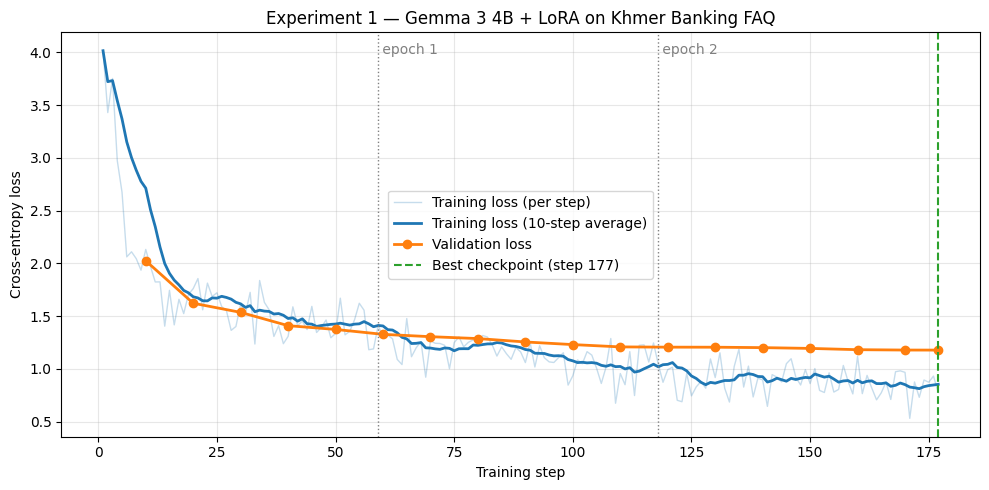

UNDERFITTING / not converged: validation loss is still decreasing at the end (1.178). Training longer (or a higher learning rate) should still help.


,Experiment 1
best_step,177
best_val_loss,1.1783
final_val_loss,1.1783
final_train_loss_smoothed,0.8536
gap,0.3247
val_rise_after_best_pct,0.0


In [14]:
import numpy as np
import matplotlib.pyplot as plt

def split_history(log_history):
    tr = pd.DataFrame([h for h in log_history if "loss" in h and "eval_loss" not in h])[["step", "epoch", "loss"]]
    ev = pd.DataFrame([h for h in log_history if "eval_loss" in h])[["step", "epoch", "eval_loss"]]
    tr["loss_smooth"] = tr["loss"].rolling(10, min_periods=1).mean()
    return tr, ev

def diagnose(tr, ev, rise_tol=0.05):
    best_i = ev.eval_loss.idxmin()
    best_step, best_loss = int(ev.step[best_i]), ev.eval_loss[best_i]
    final_val, final_train = ev.eval_loss.iloc[-1], tr.loss_smooth.iloc[-1]
    rise = (final_val - best_loss) / best_loss
    last = ev.eval_loss.tail(3).values
    still_falling = len(last) == 3 and last[0] > last[1] > last[2]
    if rise > rise_tol:
        verdict = (f"OVERFITTING: validation loss was lowest at step {best_step} ({best_loss:.3f}) and then rose "
                   f"{100*rise:.0f}% to {final_val:.3f} while training loss kept falling to {final_train:.3f}. "
                   f"Training after ~step {best_step} memorises the training answers instead of generalising.")
    elif still_falling:
        verdict = (f"UNDERFITTING / not converged: validation loss is still decreasing at the end ({final_val:.3f}). "
                   f"Training longer (or a higher learning rate) should still help.")
    else:
        verdict = (f"GOOD FIT: validation loss flattened around {best_loss:.3f} (best at step {best_step}) "
                   f"with a train/val gap of {final_val - final_train:.3f}.")
    return dict(best_step=best_step, best_val_loss=round(best_loss, 4), final_val_loss=round(final_val, 4),
                final_train_loss_smoothed=round(final_train, 4), gap=round(final_val - final_train, 4),
                val_rise_after_best_pct=round(100 * rise, 1), verdict=verdict)

def plot_losses(tr, ev, title, path):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(tr.step, tr.loss, color="tab:blue", alpha=0.25, lw=1, label="Training loss (per step)")
    ax.plot(tr.step, tr.loss_smooth, color="tab:blue", lw=2, label="Training loss (10-step average)")
    ax.plot(ev.step, ev.eval_loss, "o-", color="tab:orange", lw=2, label="Validation loss")
    b = ev.eval_loss.idxmin()
    ax.axvline(ev.step[b], color="tab:green", ls="--", lw=1.5, label=f"Best checkpoint (step {int(ev.step[b])})")
    # epoch boundaries
    for e in range(1, int(np.ceil(tr.epoch.max()))):
        s = tr.loc[(tr.epoch - e).abs().idxmin(), "step"]
        ax.axvline(s, color="gray", ls=":", lw=1); ax.text(s, ax.get_ylim()[1]*0.95, f" epoch {e}", color="gray")
    ax.set(xlabel="Training step", ylabel="Cross-entropy loss", title=title)
    ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

train_hist, eval_hist = split_history(trainer.state.log_history)
train_hist.to_csv(f"{RESULTS_DIR}/exp1_train_loss.csv", index=False)
eval_hist.to_csv(f"{RESULTS_DIR}/exp1_val_loss.csv", index=False)

plot_losses(train_hist, eval_hist, "Experiment 1 — Gemma 3 4B + LoRA on Khmer Banking FAQ", f"{RESULTS_DIR}/exp1_loss_curve.png")
diag1 = diagnose(train_hist, eval_hist)
print(diag1["verdict"])
pd.Series(diag1).drop("verdict").to_frame("Experiment 1")

In [15]:
# Validation-loss table (handy for slides)
eval_hist.assign(train_loss_smoothed = eval_hist.step.map(train_hist.set_index("step").loss_smooth),
                 gap = lambda d: d.eval_loss - d.train_loss_smoothed).round(4)

,step,epoch,eval_loss,train_loss_smoothed,gap
0,10,0.1717,2.0250,2.7135,-0.6885
1,20,0.3433,1.6226,1.6840,-0.0614
2,30,0.5150,1.5359,1.6165,-0.0807
3,40,0.6867,1.4100,1.4776,-0.0677
4,50,0.8584,1.3741,1.4252,-0.0511
5,60,1.0172,1.3276,1.4072,-0.0796
6,70,1.1888,1.3054,1.1976,0.1078
7,80,1.3605,1.2875,1.2234,0.0641
8,90,1.5322,1.2554,1.1837,0.0716
9,100,1.7039,1.2305,1.0763,0.1542


## 9. Compare results (Objective 4)

### 9.1 New dataset vs original dataset — training-loss curves
The original notebook trained 60 steps on `data_kh.csv` (robot commands). Its per-step training losses are copied below **from the saved output of `Gemma3_(4B).ipynb`**, so we can compare without re-running it.

⚠️ Absolute loss values on *different datasets* are not directly comparable (loss depends on how predictable the text is). Compare the **shape**: how fast it falls and where it levels off.

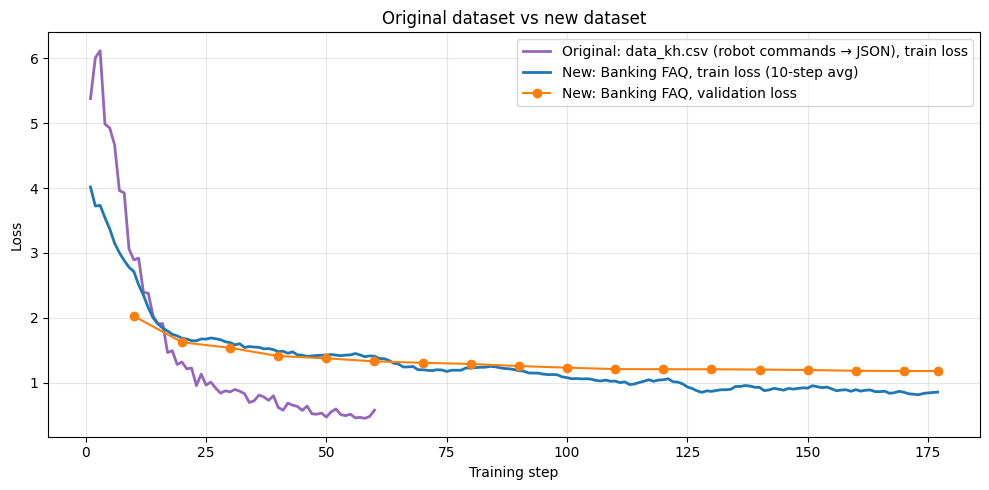

,Original (data_kh.csv),New (Banking FAQ)
task,Khmer command → JSON action,Khmer banking question → answer
train examples,2930,466
LoRA r / alpha,8 / 8,16 / 16
training,60 steps (16% of 1 epoch),3 epochs (177 steps)
validation set,none,52 examples
loss @ step 60,0.485,1.327
best val loss,n/a,1.1783


In [16]:
# Training loss per step copied from the output of the original notebook (data_kh.csv, r=8, 60 steps)
ORIGINAL_DATA_KH_LOSS = [5.3791, 6.0100, 6.1185, 4.9861, 4.9263, 4.6684, 3.9622, 3.9256, 3.0602, 2.8922,
                         2.9186, 2.3912, 2.3802, 2.0256, 1.9073, 1.9099, 1.4648, 1.4912, 1.2801, 1.3175,
                         1.2119, 1.2252, 0.9541, 1.1308, 0.9628, 1.0070, 0.9160, 0.8377, 0.8726, 0.8572,
                         0.8951, 0.8677, 0.8285, 0.6928, 0.7205, 0.8073, 0.7801, 0.7268, 0.7975, 0.6175,
                         0.5736, 0.6828, 0.6521, 0.6318, 0.5716, 0.6379, 0.5190, 0.5130, 0.5303, 0.4682,
                         0.5486, 0.5945, 0.5055, 0.4909, 0.5126, 0.4564, 0.4642, 0.4490, 0.4791, 0.5751]
orig = pd.DataFrame({"step": range(1, 61), "loss": ORIGINAL_DATA_KH_LOSS})

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(orig.step, orig.loss, color="tab:purple", lw=2, label="Original: data_kh.csv (robot commands → JSON), train loss")
ax.plot(train_hist.step, train_hist.loss_smooth, color="tab:blue", lw=2, label="New: Banking FAQ, train loss (10-step avg)")
ax.plot(eval_hist.step, eval_hist.eval_loss, "o-", color="tab:orange", label="New: Banking FAQ, validation loss")
ax.set(xlabel="Training step", ylabel="Loss", title="Original dataset vs new dataset"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/dataset_comparison.png", dpi=150); plt.show()

comparison = pd.DataFrame({
    "Original (data_kh.csv)": {"task": "Khmer command → JSON action", "train examples": 2930, "LoRA r / alpha": "8 / 8",
                               "training": "60 steps (16% of 1 epoch)", "validation set": "none",
                               "loss @ step 60": orig.loss.tail(5).mean().round(3), "best val loss": "n/a"},
    "New (Banking FAQ)": {"task": "Khmer banking question → answer", "train examples": len(train_df),
                          "LoRA r / alpha": f"{CONFIG['r']} / {CONFIG['lora_alpha']}",
                          "training": f"{CONFIG['num_train_epochs']} epochs ({int(train_hist.step.max())} steps)",
                          "validation set": f"{len(val_df)} examples",
                          "loss @ step 60": train_hist.loc[train_hist.step <= 60, "loss"].tail(5).mean().round(3),
                          "best val loss": diag1["best_val_loss"]},
})
comparison.to_csv(f"{RESULTS_DIR}/dataset_comparison.csv"); comparison

### 9.2 Before vs after fine-tuning — answer quality on unseen validation questions
Loss tells us how well the model predicts tokens; we also want to know if the **answers** got better.
We use **chrF** (character n-gram F-score) between the generated answer and the reference answer:
* it works at the **character** level, so it suits Khmer, which has no spaces between words (word-based BLEU would be meaningless);
* 0 = nothing in common, 100 = identical.

In [17]:
from sacrebleu.metrics import CHRF
chrf = CHRF()   # character n-grams (order 6), no word n-grams -> suitable for Khmer

FastModel.for_inference(model)      # best checkpoint is already loaded (load_best_model_at_end=True)
after = []
for i, q in enumerate(eval_sample.input):
    after.append(generate_answer(model, q))
    print(f"[{i+1}/{len(eval_sample)}] done")
eval_sample["after_finetune"] = after

eval_sample["chrF_before"] = [chrf.sentence_score(h, [r]).score for h, r in zip(eval_sample.before_finetune, eval_sample.output)]
eval_sample["chrF_after"]  = [chrf.sentence_score(h, [r]).score for h, r in zip(eval_sample.after_finetune,  eval_sample.output)]
corpus_before = chrf.corpus_score(list(eval_sample.before_finetune), [list(eval_sample.output)]).score
corpus_after  = chrf.corpus_score(list(eval_sample.after_finetune),  [list(eval_sample.output)]).score
print(f"\nCorpus chrF on {len(eval_sample)} unseen validation questions:  before = {corpus_before:.1f}   after = {corpus_after:.1f}")
print(f"Questions improved: {(eval_sample.chrF_after > eval_sample.chrF_before).sum()} / {len(eval_sample)}")
eval_sample.to_csv(f"{RESULTS_DIR}/before_after_answers.csv", index=False)

pd.set_option("display.max_colwidth", 200)
eval_sample[["input", "output", "before_finetune", "after_finetune", "chrF_before", "chrF_after"]].round(1)

[1/15] done
[2/15] done
[3/15] done
[4/15] done
[5/15] done
[6/15] done
[7/15] done
[8/15] done
[9/15] done
[10/15] done
[11/15] done
[12/15] done
[13/15] done
[14/15] done
[15/15] done

Corpus chrF on 15 unseen validation questions:  before = 21.9   after = 28.9
Questions improved: 10 / 15


,input,output,before_finetune,after_finetune,chrF_before,chrF_after
0,តើតម្រូវឲ្យមានឯកសារអ្វីខ្លះដើម្បីបើកគណនីអនាគតកុមារ,សម្រាប់កុមារ: ភ្ជាប់មកនូវសំបុត្រកំណើត ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬឯកសារសម្គាល់អត្តសញ្ញាណ ដែលចេញដោយអាជ្ញាធរមានសមត្ថកិច្ច។\nសម្រាប់ឪពុក-ម្តាយ ឬអ្នកអាណាព្យាបាល\nសម្រាប់ជនជាតិខ្មែរ\nត្រូវម...,ដើម្បីបើកគណនីអនាគតកុមារ (Future Kids Account) នៅក្នុងប្រទេសកម្ពុជា នោះអ្នកត្រូវមានឯកសារ និងបំពេញលក្ខណៈតម្រូវការដូចខាងក្រោមនេះ:\n\n**1. ឯកសារសំលេងលहरी (Identification Documents):**\n\n* **ឪពុកម្ត...,ត្រូវមានឯកសារដូចខាងក្រោម៖\nលិខិតបញ្ជាក់អត្តសញ្ញាណសញ្ជាតិខ្មែរច្បាប់ដើម ឬលិខិតឆ្លងដែនច្បាប់ដើម ដែលនៅមានសុពលភាពយ៉ាងតិច បីខែ ឬត្រូវមានឯកសារផ្សេងទៀតដែលអាចជំនួសបាន។\nលិខិតបញ្ជាក់អត្តសញ្ញាណនៅកន្លែងបច្ចុ...,12.3,27.8
1,ចុះបើខ្ញុំភ្លេចលេខគណនីឥណទានរបស់ខ្ញុំ,សូមទំនាក់ទំនងមកកាន់លេខរបស់ ក្រុមការងារផ្នែកផ្តល់ព័ត៌មានអតិថិជនគឺ៖ 0២៣ ៩៩១ ៥៥៥/ ០៩៨ ៩៦១ ៩៦១/ 0១៧ ៩៩១ ៥៥៥ ឬតាមរយៈការផ្ញើសារទៅកាន់គេហទំព័រផ្លូវការរបស់ធនាគារឯកទេស ខេប៊ី ដេហាន របស់យើង។,"ប្រសិនបើអ្នកភ្លេចលេខសម្표គណនីឥណទានរបស់អ្នក អ្នកអាចធ្វើតាមវិធីសាស្រ្តដូចខាងក្រោមដើម្បីសក្ដានុបត្តិចុះ:\n\n1. **연락처 은행:** ទំនាក់ទំនងទៅធនាគារដែលអ្នកមានគណនីឥណទាន។ អ្នកអាចធ្វើដូច្នេះតាមរយៈលេខទូរស័ព្ទ, ...",សូមលោកអ្នកទំនាក់ទំនងមកកាន់ការិយាល័យទំនាក់ទំនងអតិថិជន ០២៣ ៩៨៨ ៥៥៥/០១៥ ៩៨៨ ៥៥៥ ដើម្បីស្នើសុំពិនិត្យ និងទូទាត់សងប្រាក់។,20.8,22.9
2,តើឥណទាននេះមានប្រភេទរូបបិយប័ណ្ណ អ្វីខ្លះ,សម្រាប់ឥណទានអាជីវកម្មខ្នាតមធ្យម និងសាជីវកម្មផ្តល់ជូនដល់អតិថិជនជាប្រាក់រៀល ប្រាក់បាត និងប្រាក់ដុល្លារអាមេរិក។,ឥណទានមានប្រភេទរូបបិយប័ណ្ណជាច្រើនប្រភេទ ដែលអាចចែកចេញជាក្រុមធំៗ ៥ ក្រុម ដូចខាងក្រោមនេះ:\n\n1. **ឥណទានបញ្ជាក់ទ្រព្យ (Mortgage Loans):** ឥណទានប្រភេទនេះ ត្រូវបានប្រើប្រាស់ដើម្បីទិញ ឬស 건ស Buildings ដូច...,ឥណទាននេះមានប្រភេទរូបបិយប័ណ្ណជា៖ ប្រាក់រៀល ប្រាក់ដុល្លារអាមេរិក និងប្រាក់បាត។,17.5,42.7
3,តើខ្ញុំអាចដាក់ពាក្យស្នើសុំបង់រំលស់នៅកន្លែងណា,សូមធ្វើការដាក់ពាក្យស្នើសុំនៅតាមបណ្តាហាងដៃគូសហការរបស់យើងដែលមានស្លាកសញ្ញារបស់ ធនាគារឯកទេស អ៉ីអន (ខេមបូឌា) ភីអិលស៊ី ជាសម្គាល់។,អ្នកអាចដាក់ពាក្យស្នើសុំបង់រំលស់ឥណidays តាមរយៈកន្លែងជាច្រើន ដូចខាងក្រោម នេះ៖\n\n1. **សាខាបանկ:** ជាកន្លែងដែលអ្នកអាចដាក់ពាក្យស្នើសុំបង់រំលស់ឥណidays បានយ៉ាងច្រើនបំផុត។ អ្នកអាចទៅកាន់សាខាបանկដែលបានផ្ត...,លោកអ្នកអាចដាក់ពាក្យស្នើសុំបង់រំលស់នៅតាមការិយាល័យធនាគារឯកទេស អ៉ីអន (ខេមបូឌា) ភីអិលស៊ី ដែលស្ថិតនៅជិតលោកអ្នកបំផុត។,17.6,46.3
4,តើរបៀបសងត្រឡប់របស់ឥណទានពាណិជ្ជកម្មយ៉ាងដូចម្តេចដែរ,តម្រូវឲ្យសងការប្រាក់រៀងរាល់ខែ និងប្រាក់ដើមសងទៅតាមការព្រមព្រៀង។\nរាល់ការសងការ និងប្រាក់ដើមនៅចុងបញ្ចប់វដ្តនៃកម្ចី ត្រូវបានអនុញ្ញាតចំពោះ៖\nប្រភេទឥណទាន EBP ឬ OBL។\nសុវត្ថិភាពឥណទាន៖ ជាសាច់ប្រាក់ ប័ណ្ណស...,របៀបសងត្រឡប់របស់ឥណទានពាណិជ្ជកម្ម (Trade Credit Reconciliation) គឺសំខាន់ណាស់ ដើម្បីធានាថាបញ្ជីឥណទាន និងបញ្ជីបវិết (ledger) ត្រូវគ្នា និងមានភាពត្រឹមត្រូវ។ ខាងក្រោមនេះជាវិធីស 방법 ក្នុងការសងត្រឡប់ឥណទាន...,ការសងត្រឡប់របស់ឥណទានពាណិជ្ជកម្ម អាចធ្វើឡើងដូចខាងក្រោម៖\nសងរំលស់ប្រាក់ដើម និងសងការប្រាក់រៀងរាល់ខែ ។\nសងរំលស់ប្រាក់ដើមរៀងរាល់ខែ និងសងការប្រាក់ចុងខែ ។,21.7,26.9
5,តើ អ៉ីអនវ៉លឡេត គឺជាអ្វី,អ៉ីអនវ៉លឡេត គឺជាកម្មវិធីទូទាត់តាមទូរស័ព្ទដៃបង្កើតឡើងដោយ ធនាគារឯកទេស អ៉ីអន (ខេមបូឌា) ភីអិលស៊ី ហៅកាត់ថា “ASB”។ ជាមួយអ៉ីអនវ៉លឡេត លោកអ្នកអាចធ្វើការទូទាត់ថ្លៃទំនិញ បង់វិក្កយប័ត្រ បញ្ចូលកាតទូរស័ព្ទ ឬ ផ្...,អ៉ីអនវ៉លឡេត (EAN) គឺជាលេខសម្គាល់លំអិត (Unique Identifier) ដែលត្រូវបានប្រើប្រាស់ដើម្បីស្វែងរកផលិតផល ក្នុងតំបន់អឺរ៉ុప్។ នេះជាការបកស្រាយយ៉ាងពេញលេញ៖\n\n* **EAN (European Article Number):** គឺជាប្រភេ...,អ៉ីអនវ៉លឡេត គឺជាឧបករណ៍អេឡិចត្រូនិកមួយប្រភេទ ដែលមានរូបរាងជាកាត ឬកាតប័ណ្ណ ឬកាតអេឡិចត្រូនិក ដែលមានបិទរូបិយវត្ថុ នៅក្នុងកាត ដើម្បីប្រើប្រាស់ក្នុងការទូទាត់សាច់ប្រាក់ ឬកាត់ចំណាយ ឬទូទាត់ថ្លៃទំនិញ ឬកាត់ចំ...,22.2,28.5
6,តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បាន,លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បានដោយគ្រាន់តែ បើកគណនីមួយនៅធនាគារ អេស៊ីលីដា សាខាណាមួយដែលនៅជិតលោកអ្នកបំផុត ហើយគណនីនោះអាចជា គណនីបញ្ញើសំចៃ គណនីតាមតម្រូវការ ឬគណនីចរន្ត បន្ទាប់មក...,ដើម្បីស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា នោះ ត្រូវធ្វើតាមលក្ខណៈ និងដំណើរការដូចខាងក្រោមនេះ៖\n\n**1. ធានាថាអ្នកមានលក្ខណៈបឋម:**\n\n* **អាយុ:** ត្រូវមានអាយុយ៉ាងน้อย ១៨ឆ្នាំ។\n* **ប្រជាជន:...,លោក-អ្នក ត្រូវអញ្ជើញមកបំពេញពាក្យស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា តាម

In [18]:
# Side-by-side for 3 examples (good for slides)
for i in range(min(3, len(eval_sample))):
    r = eval_sample.iloc[i]
    print(f"━━━━━━━━ Example {i+1} ━━━━━━━━\nQUESTION : {r.input}\nREFERENCE: {r.output[:350]}")
    print(f"BEFORE   : {r.before_finetune[:350]}\nAFTER    : {r.after_finetune[:350]}")
    print(f"chrF before {r.chrF_before:.1f} -> after {r.chrF_after:.1f}\n")

━━━━━━━━ Example 1 ━━━━━━━━
QUESTION : តើតម្រូវឲ្យមានឯកសារអ្វីខ្លះដើម្បីបើកគណនីអនាគតកុមារ
REFERENCE: សម្រាប់កុមារ: ភ្ជាប់មកនូវសំបុត្រកំណើត ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬឯកសារសម្គាល់អត្តសញ្ញាណ ដែលចេញដោយអាជ្ញាធរមានសមត្ថកិច្ច។
សម្រាប់ឪពុក-ម្តាយ ឬអ្នកអាណាព្យាបាល
សម្រាប់ជនជាតិខ្មែរ
ត្រូវមានអត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ ឬលិខិតឆ្លងដែន (មានសុពលភាពយ៉ាងតិច ០៣ខែ) ឬ ឯកសារបញ្ជាក់ពីអត្តសញ្ញាណ ដែលមានភ្ជាប់នូវរូបថតរបស់សាមីខ្លួនដែលចេញផ្សាយដោយអាជ្ញាធរមានសមត
BEFORE   : ដើម្បីបើកគណនីអនាគតកុមារ (Future Kids Account) នៅក្នុងប្រទេសកម្ពុជា នោះអ្នកត្រូវមានឯកសារ និងបំពេញលក្ខណៈតម្រូវការដូចខាងក្រោមនេះ:

**1. ឯកសារសំលេងលहरी (Identification Documents):**

*   **ឪពុកម្តាយ/អ្នកទទួលបន្ទុក:**
    *   บัตรបឋមភោគៈ (Primary ID Card) ឬบัตรបឋមភោគៈ 2 (Primary ID Card 2)
    *   លិខិតបញ្ជាក់ថាជាឪពុកម្តាយ/អ្នកទទួលបន្ទុក (Letter of Guar
AFTER    : ត្រូវមានឯកសារដូចខាងក្រោម៖
លិខិតបញ្ជាក់អត្តសញ្ញាណសញ្ជាតិខ្មែរច្បាប់ដើម ឬលិខិតឆ្លងដែនច្បាប់ដើម ដែលនៅមានសុពលភាពយ៉ាងតិច បីខែ ឬត្រូវមានឯកសារផ្សេងទៀតដែលអាចជំនួសបាន។
លិខិតបញ្ជាក់អត្ត

### 9.3 Try your own question (live demo)
Uses Gemma 3's recommended sampling settings (`temperature=1.0, top_p=0.95, top_k=64`) and streams the answer token by token.

In [19]:
from transformers import TextStreamer
question = "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា មានសុពលភាពប៉ុន្មានឆ្នាំ"   # change me
messages = [{"role": "user", "content": [{"type": "text", "text": question}]}]
prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True).removeprefix("<bos>")
_ = model.generate(**tokenizer(text=[prompt], return_tensors="pt").to("cuda"),
                   max_new_tokens=300, do_sample=True, temperature=1.0, top_p=0.95, top_k=64,
                   streamer=TextStreamer(_tok, skip_prompt=True, skip_special_tokens=True))

ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា មានសុពលភាពដល់ ៨ឆ្នាំ គិតពីថ្ងៃចេញ។


## 10. Save the fine-tuned LoRA adapter
Only the adapter weights (a few tens of MB) are saved — not the 4B base model. To use it later, load the base model and this adapter (`FastModel.from_pretrained("gemma3_banking_lora")`).

In [20]:
model.save_pretrained("gemma3_banking_lora")
tokenizer.save_pretrained("gemma3_banking_lora")
# model.push_to_hub("YOUR_HF_USERNAME/gemma3-khmer-banking-lora", token="hf_...")   # optional online save
print("Saved to ./gemma3_banking_lora")

Unsloth: Restored added_tokens_decoder metadata in gemma3_banking_lora/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma3_banking_lora.


Saved to ./gemma3_banking_lora


## 11. (Optional) Experiment 2 — hyperparameter comparison
To show how a hyperparameter changes the loss curves, we retrain from scratch with **only one change**: a learning rate 10× smaller (`2e-4 → 2e-5`). Expectation: the loss falls much more slowly → **underfitting** within the same number of steps.

This doubles the runtime (another ~40–70 min), so it is off by default. Set `RUN_EXPERIMENT_2 = True` to run it.

In [21]:
RUN_EXPERIMENT_2 = False

if RUN_EXPERIMENT_2:
    import gc
    CONFIG_2 = {**CONFIG, "learning_rate": 2e-5}          # ONE change vs Experiment 1
    del trainer, model; gc.collect(); torch.cuda.empty_cache()
    model, tokenizer = build_model(CONFIG_2)
    trainer = build_trainer(model, CONFIG_2, output_dir="outputs_exp2")
    trainer.train()
    train_hist2, eval_hist2 = split_history(trainer.state.log_history)
    train_hist2.to_csv(f"{RESULTS_DIR}/exp2_train_loss.csv", index=False)
    eval_hist2.to_csv(f"{RESULTS_DIR}/exp2_val_loss.csv", index=False)
    diag2 = diagnose(train_hist2, eval_hist2)
    print(diag2["verdict"])

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(train_hist.step,  train_hist.loss_smooth,  color="tab:blue",  lw=2, label="Exp 1 (lr=2e-4) train")
    ax.plot(eval_hist.step,   eval_hist.eval_loss, "o-", color="tab:blue", alpha=.6, label="Exp 1 (lr=2e-4) validation")
    ax.plot(train_hist2.step, train_hist2.loss_smooth, color="tab:red",   lw=2, label="Exp 2 (lr=2e-5) train")
    ax.plot(eval_hist2.step,  eval_hist2.eval_loss, "s-", color="tab:red", alpha=.6, label="Exp 2 (lr=2e-5) validation")
    ax.set(xlabel="Training step", ylabel="Loss", title="Effect of learning rate"); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/exp1_vs_exp2_learning_rate.png", dpi=150); plt.show()
    display(pd.DataFrame({"Exp 1 (lr=2e-4)": diag1, "Exp 2 (lr=2e-5)": diag2}).drop("verdict"))

## 12. Download all results (plots + CSVs) for the presentation

In [22]:
import json, shutil
with open(f"{RESULTS_DIR}/config_exp1.json", "w") as f: json.dump(CONFIG, f, indent=2)
with open(f"{RESULTS_DIR}/diagnosis_exp1.json", "w") as f: json.dump(diag1, f, indent=2, ensure_ascii=False)
shutil.make_archive("tp3_results", "zip", RESULTS_DIR)
print(sorted(os.listdir(RESULTS_DIR)))
try:
    from google.colab import files; files.download("tp3_results.zip")
except ImportError:
    print("Saved tp3_results.zip")

['before_after_answers.csv', 'config_exp1.json', 'dataset_comparison.csv', 'dataset_comparison.png', 'diagnosis_exp1.json', 'exp1_loss_curve.png', 'exp1_train_loss.csv', 'exp1_val_loss.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>